## Simulation for the poster
Constrained optimisation on simulated data (20 x 20 D–T2 grid, 8 b-values x 8 TEs, 80 voxels, SNR 50), signal-averaged NNLS initialisation.


In [1]:
from pathlib import Path
import sys, numpy as np, matplotlib.pyplot as plt
from scipy.optimize import linear_sum_assignment
root=Path.cwd().resolve(); root=root if (root/'src').exists() else root.parent; sys.path.insert(0,str(root))
from src.optimiser_alpha_gamma import *
from src.plotting import *
from src.metrics import *
from src.signal_models import *
from src.simulation import *


rng=np.random.default_rng(40)

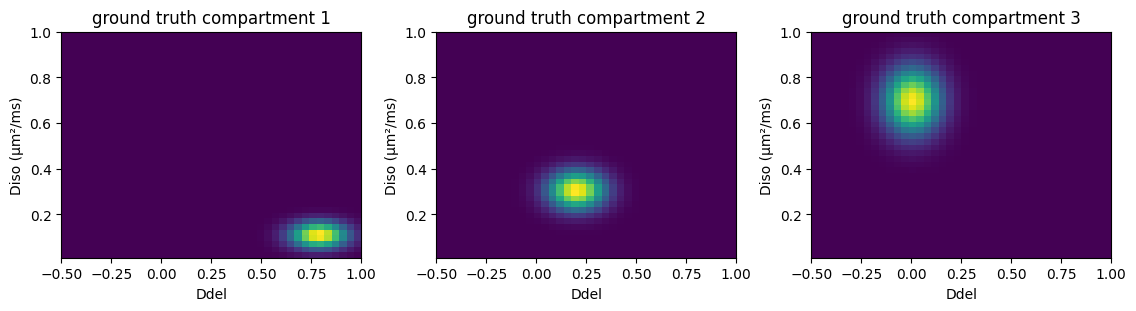

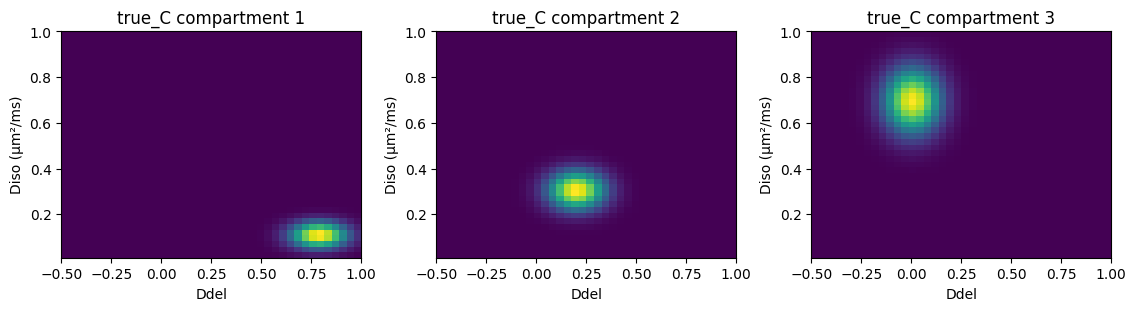

In [ ]:
#Dmin, T2min, Dmax, T2max, nD, nT2 = 0.01, 15.0, 1.0, 100.0, 40, 40
Disomin, Disomax, nDiso, Ddelmin, Ddelmax, nDdel = 0.01, 1.0, 40, -0.5, 1.0, 40

b_vals = np.array([0.0, 1.0, 2.5, 5.0, 7.5, 11.1, 18.1, 25.0])      # ms/µm²
beta_vals = np.array([-0.5, 0.0, 1.0])       # ms

voxels_to_show = [5, 10, 15, 20, 25, 30, 35]

centres = [{"Diso": 0.10, "Ddel": 0.8}, {"Diso": 0.30, "Ddel": 0.2}, {"Diso": 0.70, "Ddel": 0.0}]
widths  = [{"Diso": 0.04, "Ddel": 0.1}, {"Diso": 0.06, "Ddel": 0.1}, {"Diso": 0.10, "Ddel": 0.1}]

model = DTDModel(Disomin, Disomax, nDiso, Ddelmin, Ddelmax, nDdel)
nD, nT2 = model.shape


K = 3     # Number of canonical spectra
V = 40    # Number of voxels
R = 10    # Rank for SVD


b_list = np.repeat(b_vals, len(beta_vals))
beta_list = np.tile(beta_vals, len(b_vals))
acq = {"b": b_list, "beta": beta_list}

A = model.A(acq)

C_true = gaussian_compartments(model, centres, widths)
# GT weights
# W_true = rng.uniform(size=(K, V))
# W_true /= W_true.sum(axis=0, keepdims=True)
W_true = rng.dirichlet([0.5] * K, size=V).T     

M0_true = np.ones(V) * 300

# Signal Y = M0 * A * C_true * W_true + noise
SNR = 200
sigma = M0_true / SNR
Y = create_signal(A, C_true, W_true, M0_true, sigma, rng)

# GT C_small using SVD
U, s, Vmat = apply_SVD_to_A(A, R)
C_small_true = project_C_to_C_small(C_true, s, Vmat)

show_canonical_spectra([('ground truth', C_true)], model)
show_canonical_spectra([('true_C', C_true)], model)


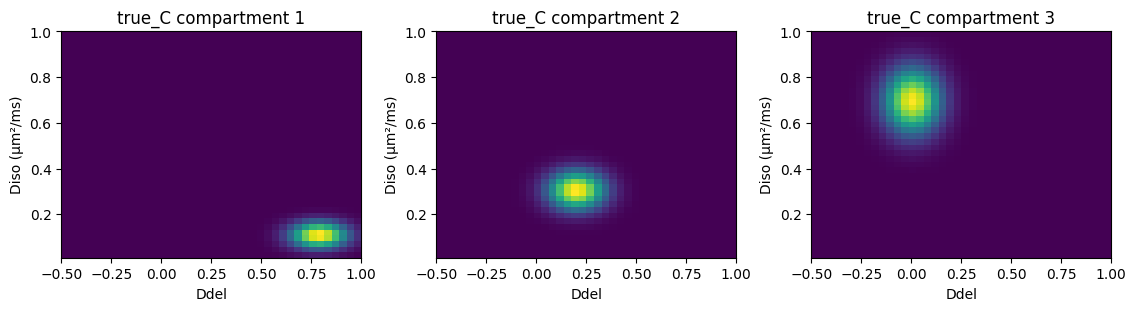

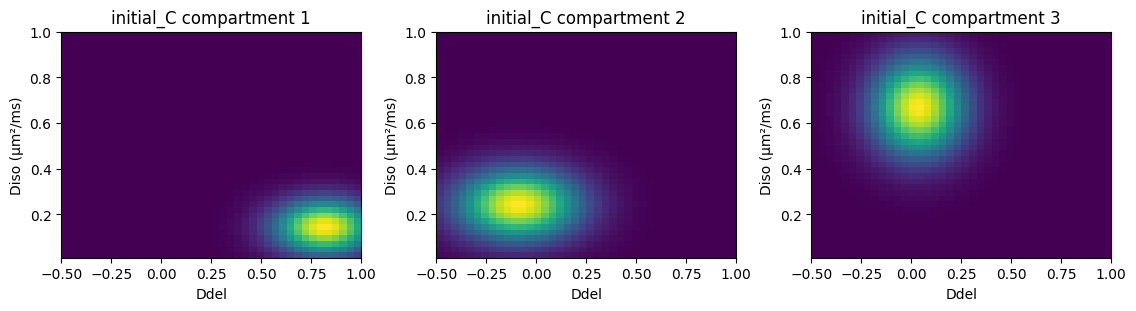

True M0: [300. 300. 300. 300. 300. 300. 300. 300. 300. 300. 300. 300. 300. 300.
 300. 300. 300. 300. 300. 300. 300. 300. 300. 300. 300. 300. 300. 300.
 300. 300. 300. 300. 300. 300. 300. 300. 300. 300. 300. 300.]
Initial M0: [298.46995709 300.12507072 300.4720215  299.20429033 299.50972958
 299.16486189 299.30455513 300.49692595 299.3342279  299.68065539
 300.84688472 300.22415637 298.08507684 299.67223297 299.23616485
 299.74414842 298.8436611  301.03273849 302.049453   299.81328507
 300.07267282 301.16498255 300.36248019 300.39595477 300.75420962
 300.22998452 298.38840347 298.39239766 300.18724133 300.55579312
 301.46796403 299.46856214 300.13176165 298.73687696 297.89704575
 299.99539717 300.14033327 299.15531271 300.8065414  299.56726112]


In [ ]:
C0 = model.initial_C(Y, A, K)

Csmall0=project_C_to_C_small(C0,s,Vmat); 

M0_init = model.initial_M0(Y, acq)

W0 = initialize_W_from_C(Y, U, Csmall0, M0_init, bound_eps=1e-3)

C0,W0=order_components(C_true, C0, W0, K)

show_canonical_spectra([('true_C', C_true)], model)
show_canonical_spectra([('initial_C', C0)], model)
print("True M0:", M0_true)
print("Initial M0:", M0_init)


### Poster figures


iter 0: loss=460.3052, fit_err=9400.624449, sigma2=9.792317
iter 100: loss=442.3725, fit_err=3666.472374, sigma2=3.819242
iter 200: loss=442.3715, fit_err=3666.478338, sigma2=3.819248
iter 300: loss=442.3696, fit_err=3666.491724, sigma2=3.819262
iter 400: loss=442.3711, fit_err=3666.478806, sigma2=3.819249
iter 500: loss=442.3713, fit_err=3666.476748, sigma2=3.819247
iter 600: loss=442.3659, fit_err=3666.473080, sigma2=3.819243
iter 700: loss=442.3658, fit_err=3666.470524, sigma2=3.819240
iter 800: loss=442.3655, fit_err=3666.471972, sigma2=3.819242
iter 900: loss=442.3520, fit_err=3666.543053, sigma2=3.819316
W MAE: 0.03864785036243338
M0 MAE: 1.2012130479075396
C MAE: 0.0005271783770982387


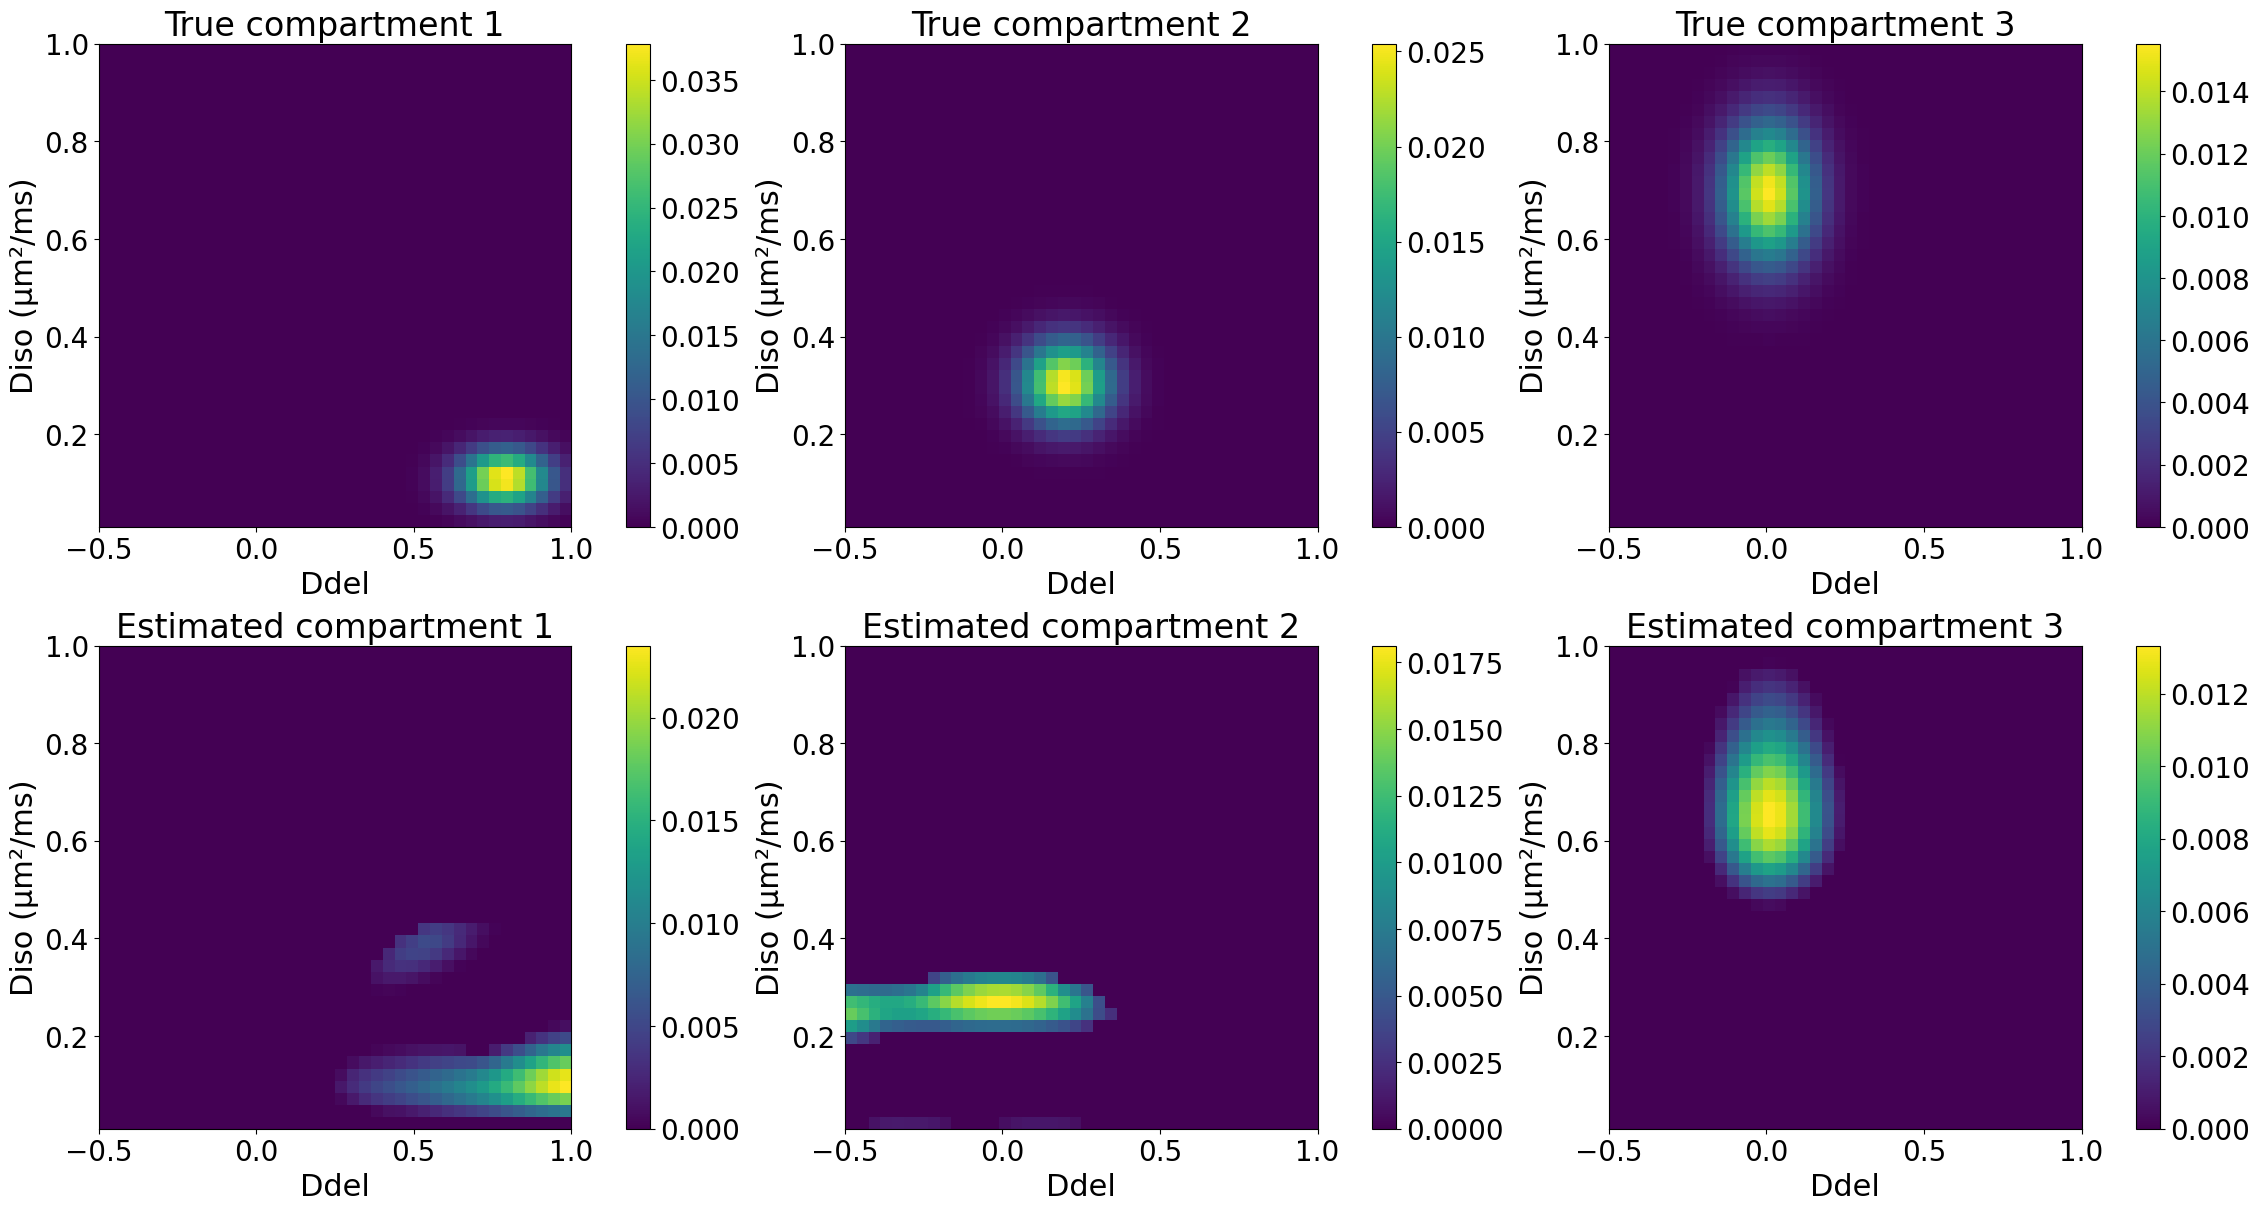

In [4]:
# Poster figures: constrained optimisation on the initial simulated dataset
# (Y, W_true, C0, W0, M0_init from the cells at the top of the notebook)

poster_voxels = [10, 20, 30]
fs = 22   # base font size

W_est_p, M0_est_p, C_est_p, alpha_est_p, sigma2_est_p, lam_est_p, losses_p, fit_errs_p = (
    run_constrained_optimisation(
        Y, U, s, Vmat,
        C0, M0_init,
        K=K,
        n_iter=1000,                   # same as real data (was 300)
        sigma2=np.mean((Y - (U @ project_C_to_C_small(C0, s, Vmat) @ W0) * M0_init) ** 2),  # from the residual, same as real data
        lam=1e-2,                      # same as real data (was 1e-8)
        W=W0,

        update_W_flag=True,
        update_C_flag=True,
        update_M0_flag=True,
        update_sigma2_flag=True,       # sigma learned, same as real data
        m0_prior=M0_init,
        m0_prior_sigma=0.1 * np.median(M0_init),   # 10% of the initial M0, same as real data,             # 10% of M0, same relative strength as real data (was 0.15)

        alpha=1.0,                     # Dirichlet prior, starting value
        update_alpha_flag=True,        # alpha learned, same as real data
        alpha_update_start=5,          # allow C/W to settle first
        weight_entropy=0.0,            # do not combine with entropy here

        c_sparsity=0.0,                # make C sparse
        c_smoothness=1000.0,            # make C smooth, same as real data (was 0)
        c_diversity=0.0,               # encourage diversity in C (is components not the same)
        c_maxiter=100,
        nD=nD,
        nT2=nT2,

        verbose_every=100,
    )
)

C_est_p, W_est_p = order_components(C_true, C_est_p, W_est_p, K)

print("W MAE:", np.mean(np.abs(W_true - W_est_p)))
print("M0 MAE:", np.mean(np.abs(M0_true - M0_est_p)))
print("C MAE:", np.mean(np.abs(C_true - C_est_p)))

F_true_p = C_true @ W_true
F_est_p = C_est_p @ W_est_p

extent = model.extent
poster_fonts = {"font.size": fs, "axes.titlesize": fs + 2, "axes.labelsize": fs,
                "xtick.labelsize": fs - 2, "ytick.labelsize": fs - 2, "legend.fontsize": fs - 2}

# Figure 1: true and estimated compartments
with plt.rc_context(poster_fonts):
    fig, axes = plt.subplots(2, K, figsize=(7.5 * K, 12), constrained_layout=True)

    for row, (name, C) in enumerate([("True", C_true), ("Estimated", C_est_p)]):
        for k in range(K):
            image = axes[row, k].imshow(C[:, k].reshape(nD, nT2), origin="lower", aspect="auto", extent=extent)
            axes[row, k].set_title(f"{name} compartment {k + 1}")
            axes[row, k].set_xlabel(model.labels[0])
            axes[row, k].set_ylabel(model.labels[1])
            fig.colorbar(image, ax=axes[row, k])

    fig.savefig("poster_simulation_compartments.png", dpi=300, bbox_inches="tight")
    plt.show()
# Figure 2: true and estimated spectra and weights for a few voxels
fs2 = 28   #

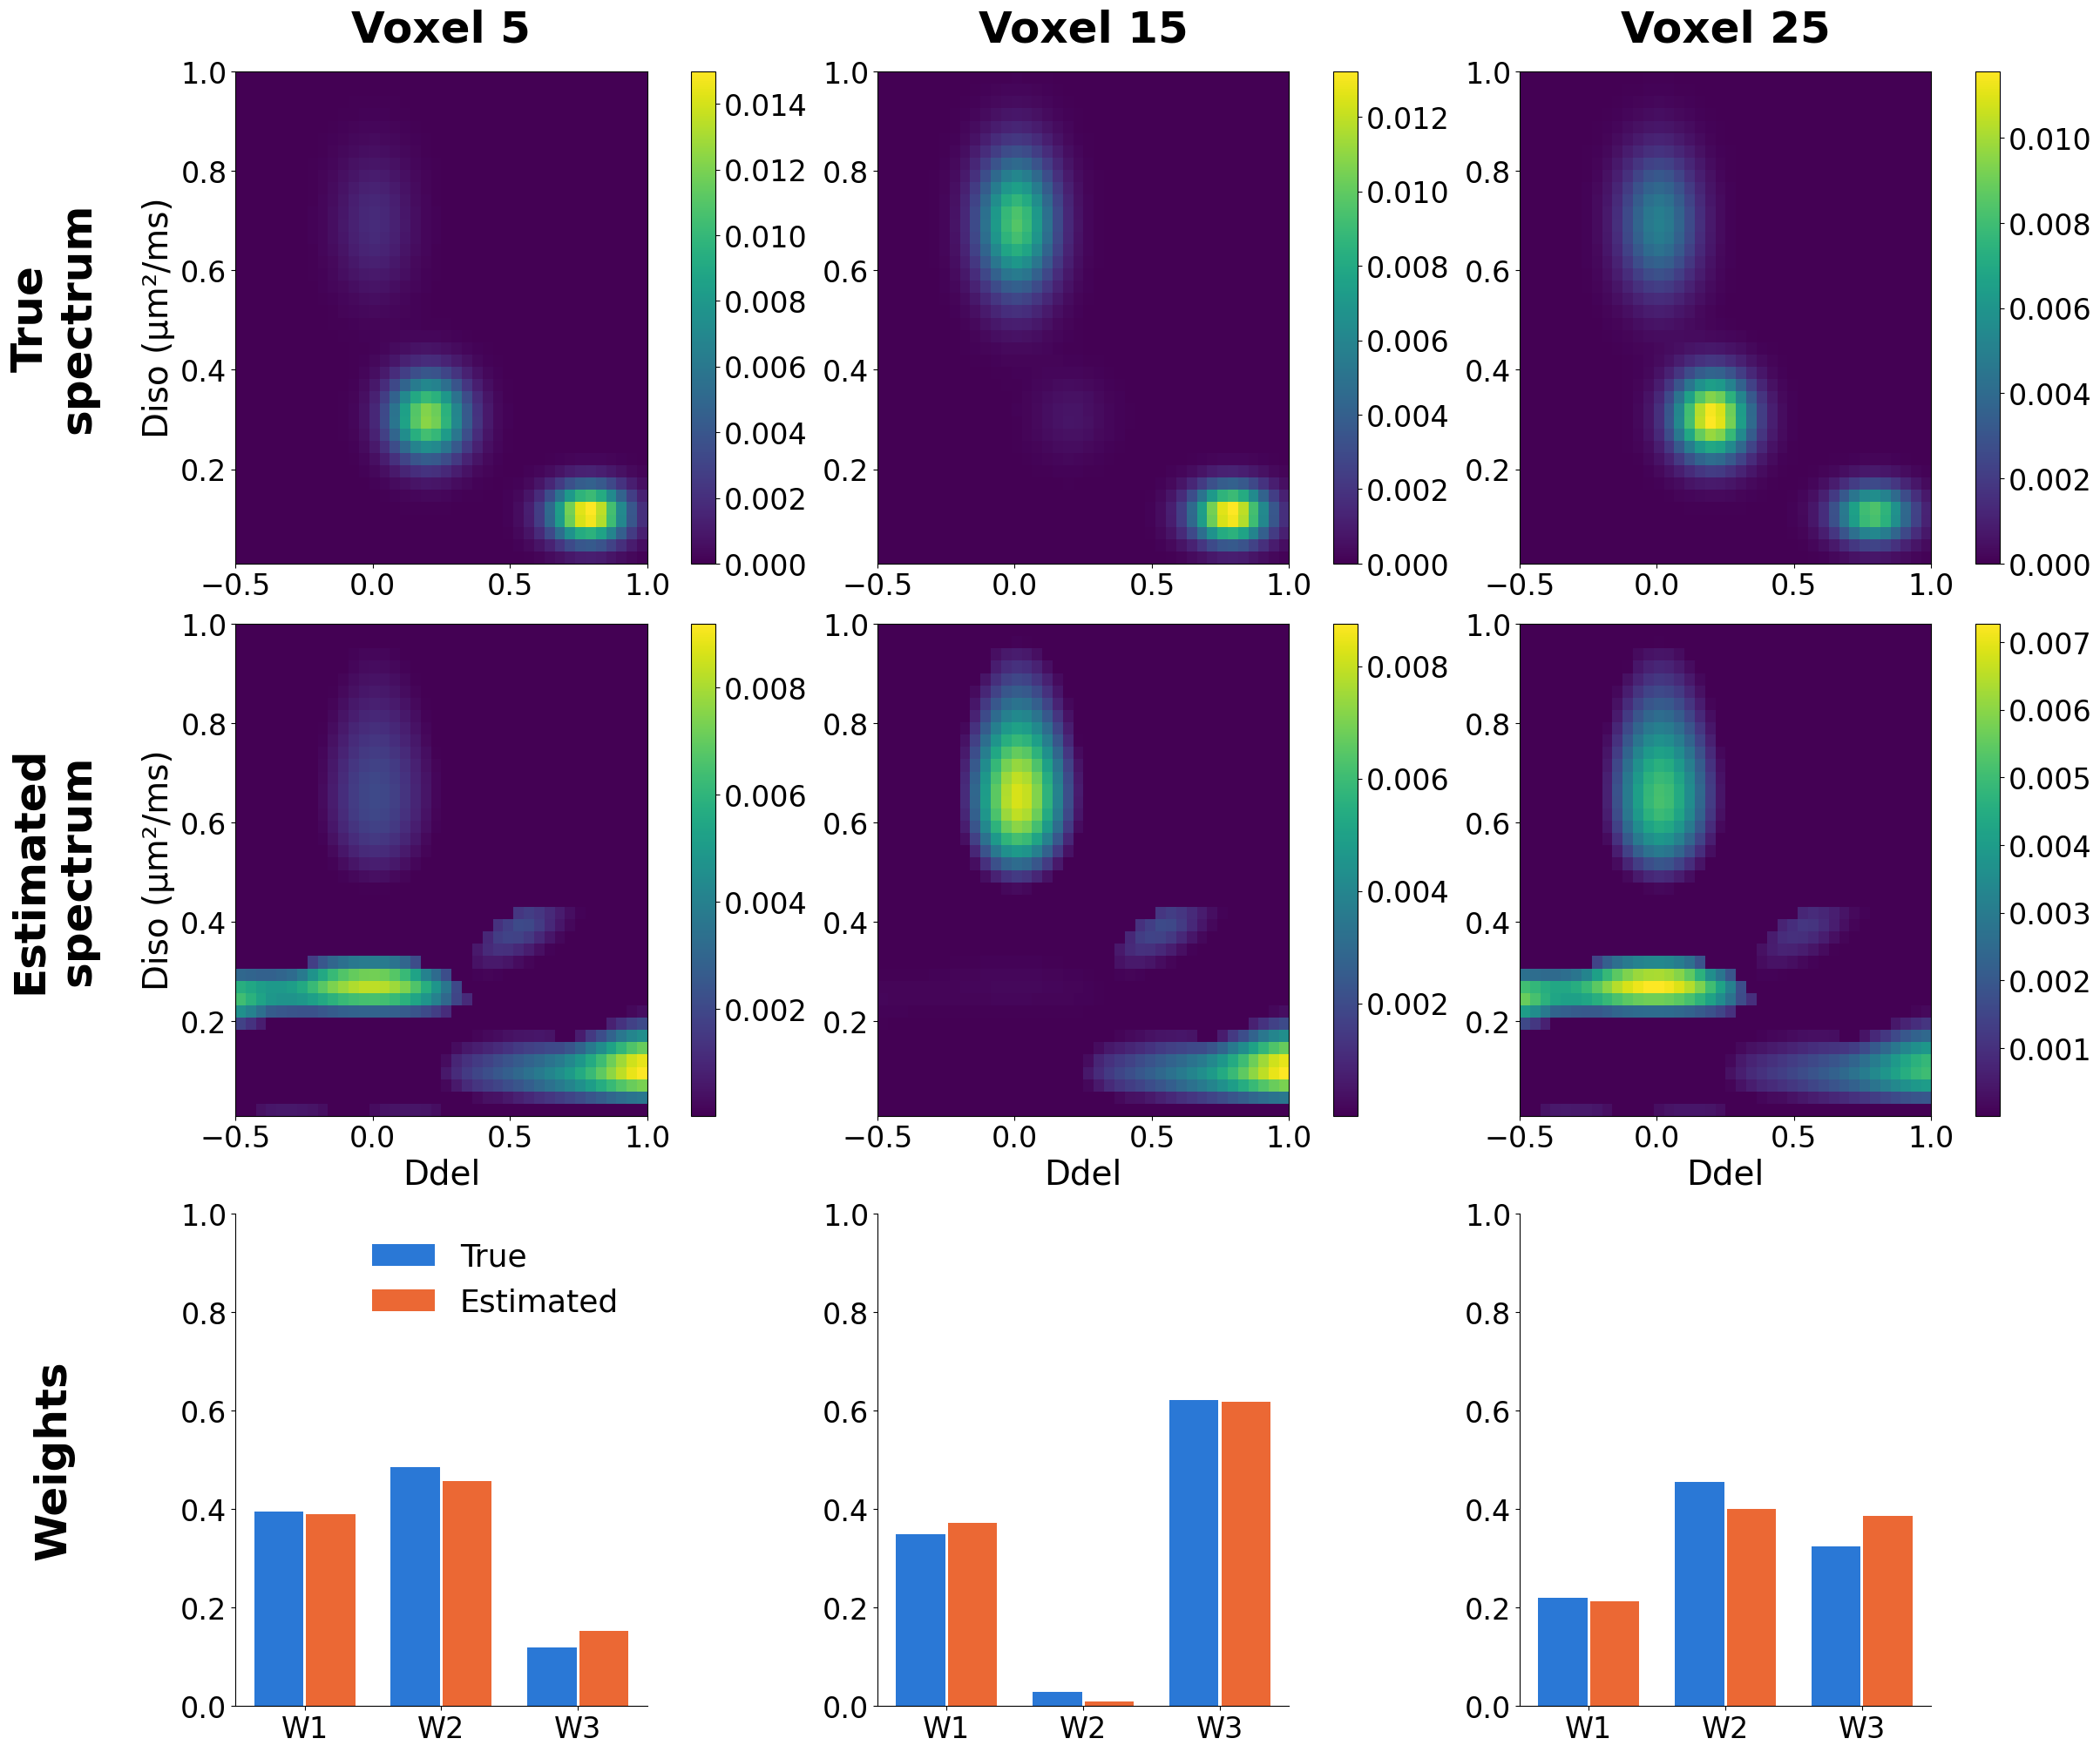

In [5]:
plot_voxel_spectra_and_weights(model, F_est_p, W_est_p, voxels=[5, 15, 25],
                               F_true=F_true_p, W_true=W_true,
                               save_path="poster_simulation_voxels.png")

### Numbers for the poster


In [6]:
# Numbers to quote next to the poster figure
W_err = np.abs(W_true - W_est_p)
M0_rel = np.abs(M0_est_p - M0_true) / M0_true
Y_fit = (A @ C_est_p @ W_est_p) * M0_est_p

print(f"Setup: {V} voxels, {A.shape[0]} measurements per voxel, SNR {SNR}, {K} compartments")
print(f"Weights: mean abs error {W_err.mean():.3f}, max {W_err.max():.3f}, correlation r = {np.corrcoef(W_true.ravel(), W_est_p.ravel())[0, 1]:.3f}")
print(f"M0: mean relative error {100 * M0_rel.mean():.1f}%")
print(f"Signal: relative residual {100 * np.linalg.norm(Y - Y_fit) / np.linalg.norm(Y):.1f}%")

# Peak position of each compartment, true vs estimated
for k in range(K):
    iD_t, iT_t = np.unravel_index(np.argmax(C_true[:, k]), (nD, nT2))
    iD_e, iT_e = np.unravel_index(np.argmax(C_est_p[:, k]), (nD, nT2))
    print(f"Compartment {k + 1} peak: true (Diso = {model.Diso_vals[iD_t]:.2f}, Ddel = {model.Ddel_vals[iT_t]:.2f}), "
          f"estimated (Diso = {model.Diso_vals[iD_e]:.2f}, Ddel = {model.Ddel_vals[iT_e]:.2f})")


Setup: 40 voxels, 24 measurements per voxel, SNR 200, 3 compartments
Weights: mean abs error 0.039, max 0.185, correlation r = 0.982
M0: mean relative error 0.4%
Signal: relative residual 1.3%
Compartment 1 peak: true (Diso = 0.11, Ddel = 0.81), estimated (Diso = 0.09, Ddel = 1.00)
Compartment 2 peak: true (Diso = 0.29, Ddel = 0.19), estimated (Diso = 0.26, Ddel = 0.00)
Compartment 3 peak: true (Diso = 0.70, Ddel = 0.00), estimated (Diso = 0.64, Ddel = 0.00)
